# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.5. K-Nearest Neighbors

*Bienvenidos* a este jupyter notebook que nos será de utilidad para predecir la especie de una flor (clasificación) a través del clasificador KNN.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Importación de bibliotecas

In [1]:
import warnings
# Ignorar todos los warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

#### Carga de los datos

In [2]:
# Cargar el dataset Iris
from sklearn.datasets import load_iris
iris = load_iris()
data = pd.DataFrame(data=iris.data, columns=iris.feature_names)
data['target'] = iris.target
data['target_name'] = data['target'].apply(lambda x: iris.target_names[x])

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
 5   target_name        150 non-null    str    
dtypes: float64(4), int32(1), str(1)
memory usage: 7.8 KB


In [4]:
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


#### Separar las entradas y la respuesta

In [5]:
selected_features = ['sepal length (cm)', 'sepal width (cm)']
#selected_features = ['petal length (cm)', 'petal width (cm)']
data = data[selected_features + ['target', 'target_name']]

In [6]:
# Separar características y etiquetas
X = data[selected_features]
y = data['target']

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Visualizar accuracy en los diferentes valores de K en train

In [9]:
accs = []
k_grid = range(1,30,2)
for k in k_grid:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    Y_pred = knn.predict(X_test)
    accs.append(accuracy_score(y_test,Y_pred))

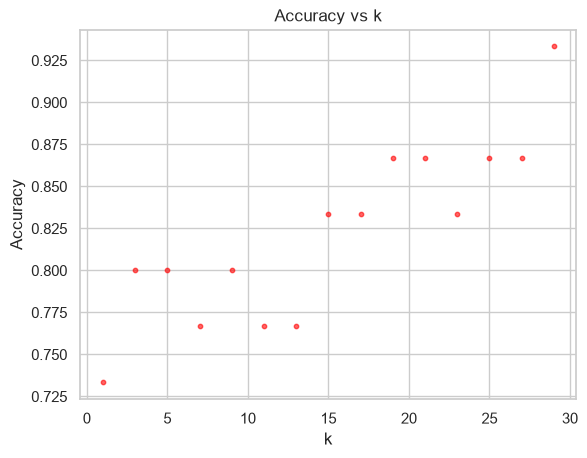

In [10]:
# Visualize.
plt.scatter(k_grid,accs,c='red',marker='o',s=10,alpha=0.6)
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('Accuracy vs k')
plt.show()

In [11]:
# Selección de k óptimo y evaluación final
optimal_k = k_grid[np.argmax(accs)]
print(f"El valor óptimo de k es: {optimal_k}")

El valor óptimo de k es: 29


In [12]:
knn = KNeighborsClassifier(n_neighbors=optimal_k)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)


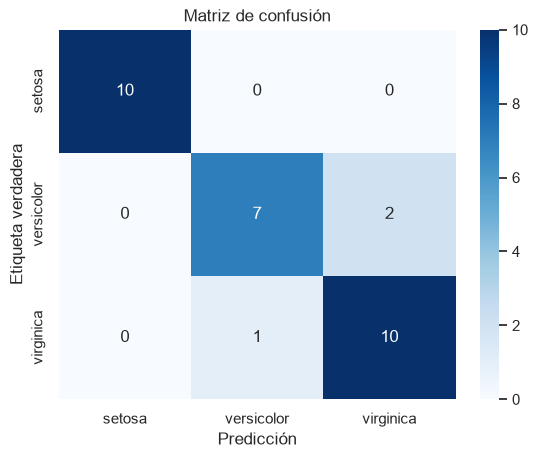

In [13]:
# Matriz de confusión
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta verdadera")
plt.show()

In [14]:
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Reporte de clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.78      0.82         9
   virginica       0.83      0.91      0.87        11

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

